In [1]:
!pip install mysql-connector-python pandas matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Atharva9860866",
    database="sales_database"
    
)

print("My Sql Connection successfully Done")

My Sql Connection successfully Done


In [4]:
sales = pd.read_sql("SELECT * FROM Sales",conn)
customers = pd.read_sql("SELECT * FROM Customers", conn)
products = pd.read_sql("SELECT * FROM Products", conn)

print("sales Data:")
display(sales.head())

print("Customers Data:")
display(customers.head())

print("Products Data:")
display(products.head())

sales Data:


C:\Users\Atharva Deshmukh\AppData\Local\Temp\ipykernel_24108\2492059462.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  sales = pd.read_sql("SELECT * FROM Sales",conn)
C:\Users\Atharva Deshmukh\AppData\Local\Temp\ipykernel_24108\2492059462.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  customers = pd.read_sql("SELECT * FROM Customers", conn)
C:\Users\Atharva Deshmukh\AppData\Local\Temp\ipykernel_24108\2492059462.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  products = pd.read_sql("SELECT * FROM Products", con

,sale_id,customer_id,product_id,quantity,sale_amount,sale_date
0,1001,1,101,2,100000.0,2026-01-10
1,1002,2,102,3,60000.0,2026-01-15
2,1003,3,103,4,20000.0,2026-02-05
3,1004,4,104,2,20000.0,2026-02-10
4,1005,5,105,5,10000.0,2026-03-01


Customers Data:


,customer_id,customer_name,region,city
0,1,Atharva,West,Mumbai
1,2,Rahul,North,Delhi
2,3,Priya,South,Bangalore
3,4,Sneha,East,Kolkata
4,5,Amit,West,Pune


Products Data:


,product_id,product_name,category,price
0,101,Laptop,Electronics,50000.0
1,102,Mobile,Electronics,20000.0
2,103,Chair,Furniture,5000.0
3,104,Table,Furniture,10000.0
4,105,Headphones,Accessories,2000.0


In [5]:
# Perform INNER JOIN using Pandas
# Combine sales, customer, and product information.
# Python built-in Pandas function: pd.merge()

In [6]:
inner_join = pd.merge(
    sales,
    customers,
    on="customer_id",
    how="inner"
)

inner_join = pd.merge(
    inner_join,
    products,
    on="product_id",
    how="inner"
)

display(inner_join)

,sale_id,customer_id,product_id,quantity,sale_amount,sale_date,customer_name,region,city,product_name,category,price
0,1001,1,101,2,100000.0,2026-01-10,Atharva,West,Mumbai,Laptop,Electronics,50000.0
1,1002,2,102,3,60000.0,2026-01-15,Rahul,North,Delhi,Mobile,Electronics,20000.0
2,1003,3,103,4,20000.0,2026-02-05,Priya,South,Bangalore,Chair,Furniture,5000.0
3,1004,4,104,2,20000.0,2026-02-10,Sneha,East,Kolkata,Table,Furniture,10000.0
4,1005,5,105,5,10000.0,2026-03-01,Amit,West,Pune,Headphones,Accessories,2000.0
5,1006,1,102,1,20000.0,2026-03-05,Atharva,West,Mumbai,Mobile,Electronics,20000.0
6,1007,2,101,1,50000.0,2026-03-10,Rahul,North,Delhi,Laptop,Electronics,50000.0
7,1008,3,105,3,6000.0,2026-03-15,Priya,South,Bangalore,Headphones,Accessories,2000.0


In [7]:
# Perform LEFT JOIN

# Display all customers, including customers without purchases.

In [8]:
left_join = pd.merge(
    customers,
    sales,
    on="customer_id",
    how="left"
)

display(left_join)

,customer_id,customer_name,region,city,sale_id,product_id,quantity,sale_amount,sale_date
0,1,Atharva,West,Mumbai,1001,101,2,100000.0,2026-01-10
1,1,Atharva,West,Mumbai,1006,102,1,20000.0,2026-03-05
2,2,Rahul,North,Delhi,1002,102,3,60000.0,2026-01-15
3,2,Rahul,North,Delhi,1007,101,1,50000.0,2026-03-10
4,3,Priya,South,Bangalore,1003,103,4,20000.0,2026-02-05
5,3,Priya,South,Bangalore,1008,105,3,6000.0,2026-03-15
6,4,Sneha,East,Kolkata,1004,104,2,20000.0,2026-02-10
7,5,Amit,West,Pune,1005,105,5,10000.0,2026-03-01


In [10]:
# Perform RIGHT JOIN

# Display all products, including products that have never been sold.

In [11]:
right_join = pd.merge(
    sales,
    products,
    on="product_id",
    how="right"
)

display(right_join)

,sale_id,customer_id,product_id,quantity,sale_amount,sale_date,product_name,category,price
0,1001,1,101,2,100000.0,2026-01-10,Laptop,Electronics,50000.0
1,1007,2,101,1,50000.0,2026-03-10,Laptop,Electronics,50000.0
2,1002,2,102,3,60000.0,2026-01-15,Mobile,Electronics,20000.0
3,1006,1,102,1,20000.0,2026-03-05,Mobile,Electronics,20000.0
4,1003,3,103,4,20000.0,2026-02-05,Chair,Furniture,5000.0
5,1004,4,104,2,20000.0,2026-02-10,Table,Furniture,10000.0
6,1005,5,105,5,10000.0,2026-03-01,Headphones,Accessories,2000.0
7,1008,3,105,3,6000.0,2026-03-15,Headphones,Accessories,2000.0


In [12]:
# Apply complex filtering conditions
# Business rules:
# - Sales amount greater than ₹10,000.
# - Quantity greater than or equal to 2.
# - Category is Electronics or Furniture.
# - Region is West or North.
# - Sales date between January and March 2026.

In [13]:
inner_join["sale_date"] = pd.to_datetime(inner_join["sale_date"])

In [14]:
filtered_data = inner_join[
    (inner_join["sale_amount"] > 10000) &
    (inner_join["quantity"] >= 2) &
    (inner_join["category"].isin(["Electronics","Furniture"])) & 
    (inner_join["region"].isin(["West","North"])) &
    (inner_join["sale_date"].between("2026-01-01", "2026-03-31"))
]

display(filtered_data)

,sale_id,customer_id,product_id,quantity,sale_amount,sale_date,customer_name,region,city,product_name,category,price
0,1001,1,101,2,100000.0,2026-01-10,Atharva,West,Mumbai,Laptop,Electronics,50000.0
1,1002,2,102,3,60000.0,2026-01-15,Rahul,North,Delhi,Mobile,Electronics,20000.0


In [15]:
# Calculate total sales by region
# Pandas functions: groupby() and agg()

In [16]:
region_sales = inner_join.groupby("region").agg(
    total_sales=("sale_amount","sum"),
    total_orders=("sale_id","count"),
    average_sales=("sale_amount","mean")
).reset_index()

region_sales = region_sales.sort_values(
    by="total_sales",
    ascending=False
)

display(region_sales)

,region,total_sales,total_orders,average_sales
3,West,130000.0,3,43333.333333
1,North,110000.0,2,55000.000000
2,South,26000.0,2,13000.000000
0,East,20000.0,1,20000.000000


In [17]:
# Calculate total sales by product

In [18]:
product_sales = inner_join.groupby(
    ["product_name", "category"]
).agg(
    total_quantity=("quantity", "sum"),
    total_sales=("sale_amount", "sum"),
    average_sales=("sale_amount", "mean")
).reset_index()

product_sales = product_sales.sort_values(
    by="total_sales",
    ascending=False
)

display(product_sales)

,product_name,category,total_quantity,total_sales,average_sales
2,Laptop,Electronics,3,150000.0,75000.0
3,Mobile,Electronics,4,80000.0,40000.0
0,Chair,Furniture,4,20000.0,20000.0
4,Table,Furniture,2,20000.0,20000.0
1,Headphones,Accessories,8,16000.0,8000.0


In [19]:
# Calculate total sales by customer

In [20]:
customer_sales = inner_join.groupby(
    ["customer_name", "region"]
).agg(
    total_orders=("sale_id", "count"),
    total_quantity=("quantity", "sum"),
    total_sales=("sale_amount", "sum")
).reset_index()

customer_sales = customer_sales.sort_values(
    by="total_sales",
    ascending=False
)

display(customer_sales)

,customer_name,region,total_orders,total_quantity,total_sales
1,Atharva,West,2,3,120000.0
3,Rahul,North,2,4,110000.0
2,Priya,South,2,7,26000.0
4,Sneha,East,1,2,20000.0
0,Amit,West,1,5,10000.0


In [21]:
#  Customer segmentation using apply()
# Business rule:
# - ₹100,000 or above: Premium Customer.
# - ₹50,000 or above: Regular Customer.
# - Below ₹50,000: Basic Customer.

In [22]:
def customer_category(amount):

    if amount >= 100000:
        return "Premium Customer"

    elif amount >= 50000:
        return "Regular Customer"

    else:
        return "Basic Customer"


customer_sales["customer_segment"] = customer_sales[
    "total_sales"
].apply(customer_category)

display(customer_sales)

,customer_name,region,total_orders,total_quantity,total_sales,customer_segment
1,Atharva,West,2,3,120000.0,Premium Customer
3,Rahul,North,2,4,110000.0,Premium Customer
2,Priya,South,2,7,26000.0,Basic Customer
4,Sneha,East,1,2,20000.0,Basic Customer
0,Amit,West,1,5,10000.0,Basic Customer


In [23]:
# Find top 5 customers

In [24]:
top_customers = customer_sales.nlargest(
    5,
    "total_sales"
)

display(top_customers)

,customer_name,region,total_orders,total_quantity,total_sales,customer_segment
1,Atharva,West,2,3,120000.0,Premium Customer
3,Rahul,North,2,4,110000.0,Premium Customer
2,Priya,South,2,7,26000.0,Basic Customer
4,Sneha,East,1,2,20000.0,Basic Customer
0,Amit,West,1,5,10000.0,Basic Customer


In [25]:
# Find best-selling product

In [26]:
best_product = product_sales.loc[
    product_sales["total_sales"].idxmax()
]

print("Best selling Product:- ")
print(best_product)

Best selling Product:- 
product_name           Laptop
category          Electronics
total_quantity              3
total_sales          150000.0
average_sales         75000.0
Name: 2, dtype: object


In [27]:
# Find total revenue

In [29]:
total_revenue = inner_join["sale_amount"].sum()
average_order_values = inner_join["sale_amount"].mean()
total_orders = inner_join["sale_id"].nunique()

print("Total Revenue:", total_revenue)
print("Average Order Value:", average_order_values)
print("Total Orders:", total_orders)

Total Revenue: 286000.0
Average Order Value: 35750.0
Total Orders: 8


In [30]:
# Visualize sales by product

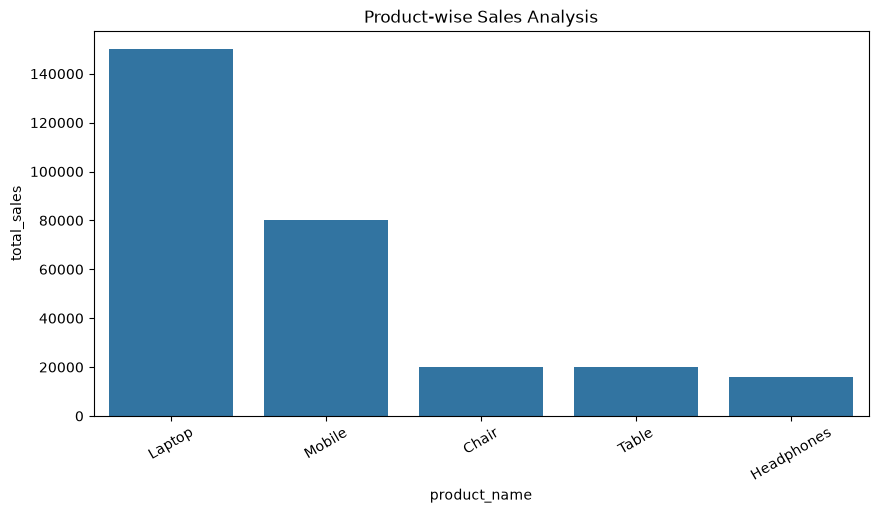

In [31]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=product_sales,
    x="product_name",
    y="total_sales"
)

plt.title("Product-wise Sales Analysis")
plt.xticks(rotation=30)

plt.show()

In [32]:
# Visualize customer segmentation

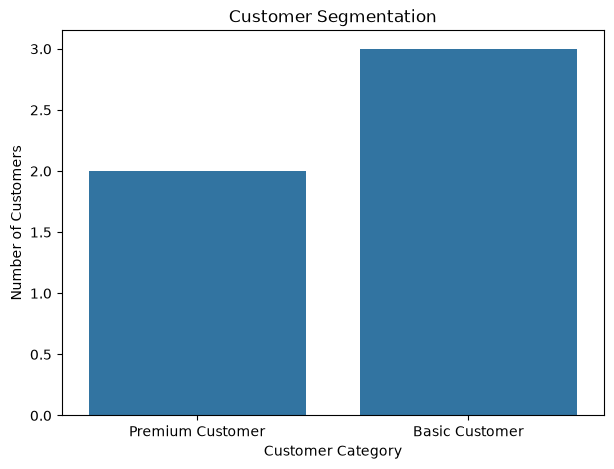

In [33]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=customer_sales,
    x="customer_segment"
)

plt.title("Customer Segmentation")
plt.xlabel("Customer Category")
plt.ylabel("Number of Customers")

plt.show()